In [129]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [130]:
tickers = ["QQQ", "EEM", "IWM", "SOXL"]
assets = {}

for t in tickers:
    df = yf.download(t, start="2000-01-01", auto_adjust=True)
    
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    df = df[["Open", "High", "Low", "Close", "Volume"]].dropna()
    assets[t] = df

    # common trading dates
common_dates = sorted(set.intersection(*[set(df.index) for df in assets.values()]))

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [131]:
def trend_mr_signal(df, date, fast=20, slow=200, entry_z=1.5, exit_z=0.7):
    if date not in df.index:
        return 0, 0.0

    close = df["Close"]
    idx = close.index.get_loc(date)

    if idx < slow + 5:
        return 0, 0.0

    price = close.iloc[idx]
    fast_ma = close.rolling(fast).mean().iloc[idx]
    slow_ma = close.rolling(slow).mean().iloc[idx]
    slow_ma_prev = close.rolling(slow).mean().iloc[idx - 5]
    std = close.rolling(fast).std().iloc[idx]

    if std == 0 or np.isnan(std):
        return 0, 0.0

    z = (price - fast_ma) / std

    bull = price > slow_ma and slow_ma > slow_ma_prev
    bear = price < slow_ma and slow_ma < slow_ma_prev

    if bull and z < -entry_z:
        return +1, z
    if bear and z > entry_z:
        return -1, z

    if abs(z) < exit_z:
        return 0, z

    return 0, z

In [132]:
def calc_vol(df, date, lookback=20):
    if date not in df.index:
        return np.nan

    idx = df.index.get_loc(date)
    if idx < lookback:
        return np.nan

    returns = df["Close"].pct_change()
    vol = returns.rolling(lookback).std().iloc[idx] * np.sqrt(252)
    return vol


def inverse_vol_weights(vols):
    inv = {k: 1 / v for k, v in vols.items() if v > 0}
    total = sum(inv.values())
    return {k: inv[k] / total for k in inv}


def portfolio_vol(weights, vols):
    return np.sqrt(sum((weights[k] * vols[k]) ** 2 for k in weights))


def z_conviction(z, entry_z, cap_z=3.0):
    az = abs(z)
    if az < entry_z:
        return 0.0
    if az >= cap_z:
        return 1.0
    return (az - entry_z) / (cap_z - entry_z)
    

#def high_vol_regime(mkt_df, date, lookback=60, threshold=0.75):
    #idx = mkt_df.index.get_loc(date)
    #if idx < lookback:
        #return False

    #vol = mkt_df["Close"].pct_change().rolling(lookback).std().iloc[idx]
    #vol_long = mkt_df["Close"].pct_change().rolling(252).std().iloc[idx]

    #return vol > threshold * vol_long

In [133]:
def pure_trend_signal(df, date, fast=50, slow=200):
    if date not in df.index:
        return 0

    fast_ma = df["Close"].rolling(fast).mean().loc[date]
    slow_ma = df["Close"].rolling(slow).mean().loc[date]

    if pd.isna(fast_ma) or pd.isna(slow_ma):
        return 0

    if fast_ma > slow_ma:
        return +1
    elif fast_ma < slow_ma:
        return -1
    else:
        return 0

In [134]:
RISK_BUDGET_MR    = 0.5   # 50% of portfolio risk
RISK_BUDGET_TREND = 0.5 

In [135]:
def run_portfolio_backtest(
    assets,
    dates,
    start_equity=100_000,
    target_portfolio_vol=0.18,
):
    #mkt_df = assets["QQQ"]
    
    equity = start_equity
    equity_curve = []

    for i, date in enumerate(dates[:-1]):
        vols = {}
        signals = {}
        z_scores = {}

        # --- per-asset signal & vol ---
        # --- per-asset signal & vol ---
        for ticker, df in assets.items():
        
            vol = calc_vol(df, date)
            if np.isnan(vol) or vol <= 0:
                continue
        
            mr_signal, z = trend_mr_signal(df, date)
            trend_signal = pure_trend_signal(df, date)
        
            vols[ticker] = vol
            signals[ticker] = {
                "mr": mr_signal,
                "trend": trend_signal
            }
            z_scores[ticker] = z

        if len(vols) == 0:
            equity_curve.append(equity)
            continue

        # --- allocation ---
        weights = inverse_vol_weights(vols)
        port_vol = portfolio_vol(weights, vols)
        
        scale = target_portfolio_vol / port_vol
        #scale = min(scale, 2.5)
        

        # ---- VOLATILITY REGIME GATE (HERE) ----
        #if high_vol_regime(mkt_df, date):
            #scale *= 0.4


        positions = {}

        for ticker in weights:

            mr_conviction = z_conviction(
                z_scores[ticker],
                entry_z=1.5,
                cap_z=3.0
            )
        
            w_mr = (
                weights[ticker]
                * signals[ticker]["mr"]
                * mr_conviction
                * RISK_BUDGET_MR
            )
        
            w_trend = (
                weights[ticker]
                * signals[ticker]["trend"]
                * RISK_BUDGET_TREND
            )
            
            positions[ticker] = (w_mr + w_trend) * scale

        daily_pnl = 0.0

        for ticker, exposure in positions.items():
            df = assets[ticker]
            idx = df.index.get_loc(date)
            ret = df["Close"].pct_change().iloc[idx + 1]
            daily_pnl += equity * exposure * ret

        # update equity
        equity += daily_pnl
        equity_curve.append(equity)

    return pd.Series(equity_curve, index=dates[:len(equity_curve)])      

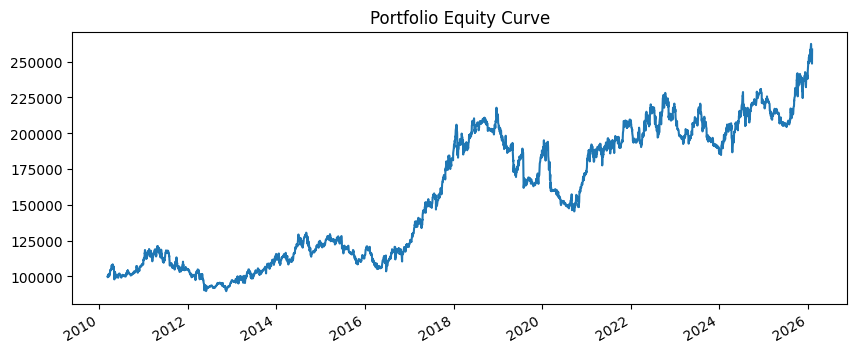

Final Equity: 258448.08
CAGR: 0.0617
Vol: 0.1542
Sharpe: 0.466
Max DD: -0.3325
Realized vol: 0.15416165736873244
<class 'pandas.core.series.Series'>


In [143]:
equity = run_portfolio_backtest(assets, common_dates)

equity.plot(figsize=(10,4), title="Portfolio Equity Curve")
plt.show()


returns = equity.pct_change().dropna()

cagr = (equity.iloc[-1] / equity.iloc[0]) ** (252 / len(returns)) - 1
vol = returns.std() * np.sqrt(252)
sharpe = returns.mean() * 252 / vol
dd = (equity - equity.cummax()) / equity.cummax()
realized_vol = returns.std() * np.sqrt(252)



print("Final Equity:", round(equity.iloc[-1], 2))
print("CAGR:", round(cagr, 4))
print("Vol:", round(vol, 4))
print("Sharpe:", round(sharpe, 3))
print("Max DD:", round(dd.min(), 4))
print("Realized vol:", realized_vol)
print(type(equity))


In [148]:
#ADD DRAWDOWN DURATION CODE NOW!! THEN WALKFORWARD IT!!!

import pandas as pd
import numpy as np

def drawdown_duration(equity):
    equity = equity.dropna()

    running_max = equity.cummax()
    drawdown = equity / running_max - 1
    
    dd_durations = []
    current_duration = 0
    
    for dd in drawdown:
        if dd < 0:
            current_duration += 1
        else:
            if current_duration > 0:
                dd_durations.append(current_duration)
                current_duration = 0

    if current_duration > 0:
            dd_durations.append(current_duration)
    
    if not dd_durations:
        return {
            "num_dd": 0,
            "max_dd_duration": 0,
            "avg_dd_duration": 0,
            "median_dd_duration": 0
        }
    
    return {
        "num_dd": len(dd_durations),
        "max_dd_duration": max(dd_durations),
        "avg_dd_duration": np.mean(dd_durations),
        "median_dd_duration": np.median(dd_durations)
    }

In [149]:
def walkforward_splits(dates, train_years=3, test_years=1):
    dates = pd.to_datetime(dates)
    splits = []

    start = dates.min()

    while True:
        train_end = start + pd.DateOffset(years=train_years)
        test_end  = train_end + pd.DateOffset(years=test_years)

        train_dates = dates[(dates >= start) & (dates < train_end)]
        test_dates  = dates[(dates >= train_end) & (dates < test_end)]

        if len(test_dates) == 0:
            break

        splits.append((train_dates, test_dates))
        start = train_end

    return splits

In [150]:
def run_walkforward(assets, dates):
    wf_results = []

    splits = walkforward_splits(dates, train_years=3, test_years=1)

    for i, (train_dates, test_dates) in enumerate(splits, 1):

        # run only on TEST window
        equity = run_portfolio_backtest(assets, test_dates)

        returns = equity.pct_change().dropna()

        cagr = (equity.iloc[-1] / equity.iloc[0]) ** (252 / len(returns)) - 1
        vol = returns.std() * np.sqrt(252)
        sharpe = returns.mean() * 252 / vol

        dd_stats = drawdown_duration(equity)

        wf_results.append({
            "window": i,
            "start": test_dates[0],
            "end": test_dates[-1],
            "CAGR": cagr,
            "Vol": vol,
            "Sharpe": sharpe,
            "Max_DD_Duration": dd_stats["max_dd_duration"],
        })

    return pd.DataFrame(wf_results)

In [151]:
wf_results = run_walkforward(assets, common_dates)
wf_results

,window,start,end,CAGR,Vol,Sharpe,Max_DD_Duration
0,1,2013-03-11,2014-03-10,0.160226,0.154474,1.039543,50
1,2,2016-03-11,2017-03-10,0.242040,0.180206,1.293894,64
2,3,2019-03-11,2020-03-10,-0.107919,0.190335,-0.504210,177
3,4,2022-03-11,2023-03-10,-0.055099,0.166104,-0.258431,100
4,5,2025-03-11,2026-02-06,0.251725,0.153803,1.537263,89


In [ ]:
#STITCHED EQUITY:

In [152]:
#stitched equity

def run_walkforward_equity(assets, dates):
    wf_equity = []

    splits = walkforward_splits(dates, train_years=3, test_years=1)

    for train_dates, test_dates in splits:
        # run ONLY on test window
        equity = run_portfolio_backtest(assets, test_dates)

        # avoid overlapping first point
        if len(wf_equity) > 0:
            equity = equity.iloc[1:]

        wf_equity.append(equity)

    # stitch all OOS segments
    wf_equity = pd.concat(wf_equity)
    return wf_equity

In [153]:
wf_equity = run_walkforward_equity(assets, common_dates)

wf_returns = wf_equity.pct_change().dropna()

wf_cagr = (wf_equity.iloc[-1] / wf_equity.iloc[0]) ** (252 / len(wf_returns)) - 1
wf_vol = wf_returns.std() * np.sqrt(252)
wf_sharpe = wf_returns.mean() * 252 / wf_vol

wf_dd = (wf_equity - wf_equity.cummax()) / wf_equity.cummax()
wf_max_dd = wf_dd.min()

In [154]:
# drawdown duration on stitched WF equity
dd_durations = []
current_duration = 0

for dd in wf_dd:
    if dd < 0:
        current_duration += 1
    else:
        if current_duration > 0:
            dd_durations.append(current_duration)
            current_duration = 0

if current_duration > 0:
    dd_durations.append(current_duration)

wf_max_dd_duration = max(dd_durations) if dd_durations else 0

In [155]:
print("WF Final Equity:", round(wf_equity.iloc[-1], 2))
print("WF CAGR:", round(wf_cagr, 4))
print("WF Vol:", round(wf_vol, 4))
print("WF Sharpe:", round(wf_sharpe, 3))
print("WF Max DD:", round(wf_max_dd, 4))
print("WF Max DD Duration (days):", wf_max_dd_duration)

WF Final Equity: 122750.39
WF CAGR: 0.0441
WF Vol: 0.2092
WF Sharpe: 0.314
WF Max DD: -0.3312
WF Max DD Duration (days): 735


In [45]:
#improvements or additions:
#removing vol cap...originally it was scale = min(target_portfolio_vol / port_vol, 1.3)

In [ ]:
#observations:
'''
only removing the vol cap truly improved metrics ie increased cagr and inc volatility too

adding the min 2.5 scale reduced it further

followed by part 2 filters: tail filters: 2A & 2B progressively reduced CAGR but also greatly reduced volatility and sharpe..

'''

#Note ive returned it to the vol cap removed stage(highest cagr, sharpe & volatility)p by "#"ing all the subsequent filters..